# SLC model development and locked-test evaluation

This notebook summarises the results produced by the project code. Five predefined model types were compared using the 500 participants in the development set. Model selection, sigmoid calibration, and threshold selection were completed using development data only. After these choices were fixed, the final models were evaluated once using the 125 participants in the locked test set. This notebook reads the saved aggregate reports; it does not train the models again or display individual participant records. The results are for research purposes and should not be treated as a clinical diagnosis.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

def find_repository_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'pyproject.toml').is_file() and (candidate / 'training').is_dir():
            return candidate
    raise RuntimeError('Run this notebook from inside the repository.')

ROOT = find_repository_root()
REPORT_DIR = ROOT / 'reports' / 'generated'
paths = {
    'comparison': REPORT_DIR / 'development-model-comparison-report.json',
    'calibration': REPORT_DIR / 'development-calibration-report.json',
    'decision': REPORT_DIR / 'development-decision-report.json',
    'final': REPORT_DIR / 'final-locked-test-report.json',
}
missing = [path.name for path in paths.values() if not path.is_file()]
if missing:
    raise FileNotFoundError(f'Missing generated reports: {missing}')
reports = {name: json.loads(path.read_text(encoding='utf-8')) for name, path in paths.items()}
comparison = reports['comparison']; calibration = reports['calibration']
decision = reports['decision']; final = reports['final']
assert comparison['scope'] == 'development_only'
assert comparison['final_test_evaluated'] is False
assert calibration['final_test_evaluated'] is False
assert decision['final_test_evaluated'] is False
assert final['status'] == 'completed_one_time_locked_test_evaluation'
assert final['final_test_evaluated'] is True
assert final['models_refit_or_adjusted_on_final_test'] is False
assert final['thresholds_adjusted_on_final_test'] is False
assert len(comparison['candidates']) == 5
assert len({report['dataset_sha256'] for report in reports.values()}) == 1
assert len({report['split_fingerprint_sha256'] for report in reports.values()}) == 1
display(Markdown('**Evidence checks passed:** all reports describe the same dataset and split.'))

**Evidence checks passed:** all reports describe the same dataset and split.

## Target scoring and ML operating thresholds

Two different types of threshold are used in this project. A follow-up questionnaire score of 50% or below defines the observed concern label in the dataset. An ML probability threshold is then used to convert a model probability into a concern or no-concern prediction. These thresholds are not the same thing.

A model was selected separately for each domain using the highest mean Average Precision from repeated cross-validation. Sigmoid calibration used nested out-of-fold predictions from the development set. The threshold for each domain was selected by maximising balanced accuracy, which is equivalent to maximising Youden's J. If thresholds produced the same result, the procedure preferred higher sensitivity, then higher specificity, and finally the lower threshold. The selected thresholds were fixed before the locked test was opened and were not changed after seeing the test results.

In [2]:
domain_order = ['target_communication_concern', 'target_cognitive_concern', 'target_social_emotional_concern']
selection_rows = []
ranking_rows = []
for target in domain_order:
    domain = decision['domains'][target]
    selected = domain['candidate_ranking'][0]
    threshold = domain['threshold_selection']
    metrics = threshold['metrics']
    selection_rows.append({
        'Domain': domain['display_name'], 'Selected model': domain['model_configuration_version'],
        'Development mean AP': selected['average_precision_mean'],
        'Frozen threshold': threshold['threshold'],
        'Sensitivity': metrics['sensitivity'], 'Specificity': metrics['specificity'],
        'Balanced accuracy': metrics['balanced_accuracy'],
    })
    for candidate in domain['candidate_ranking']:
        ranking_rows.append({
            'Domain': domain['display_name'], 'Rank': candidate['rank'],
            'Candidate': candidate['candidate'], 'Mean AP': candidate['average_precision_mean'],
            'AP SD': candidate['average_precision_standard_deviation'],
            'Mean AUROC': candidate['roc_auc_mean'], 'Mean Brier': candidate['brier_score_mean'],
        })
selection = pd.DataFrame(selection_rows).set_index('Domain')
display(selection.style.format({'Development mean AP': '{:.4f}', 'Frozen threshold': '{:.6f}',
    'Sensitivity': '{:.2%}', 'Specificity': '{:.2%}', 'Balanced accuracy': '{:.2%}'}))
rankings = pd.DataFrame(ranking_rows).sort_values(['Domain', 'Rank'])
display(rankings.style.format({'Mean AP': '{:.4f}', 'AP SD': '{:.4f}',
    'Mean AUROC': '{:.4f}', 'Mean Brier': '{:.4f}'}).hide(axis='index'))

,Selected model,Development mean AP,Frozen threshold,Sensitivity,Specificity,Balanced accuracy
Domain,,,,,,
Communication,xgboost-regularized-balanced-v1,0.5020,0.130882,81.97%,72.89%,77.43%
Cognitive,logistic-l2-balanced-v1,0.5444,0.109680,94.34%,74.94%,84.64%
Social-emotional,xgboost-regularized-balanced-v1,0.5899,0.126137,84.75%,83.22%,83.98%


Domain,Rank,Candidate,Mean AP,AP SD,Mean AUROC,Mean Brier
Cognitive,1,logistic_l2_balanced,0.5444,0.0124,0.8854,0.1221
Cognitive,2,xgboost_regularized_balanced,0.5171,0.0242,0.8826,0.1056
Cognitive,3,svm_rbf_balanced,0.3689,0.0255,0.8538,0.0801
Cognitive,4,extra_trees_balanced_leaf5,0.3513,0.0221,0.8634,0.1132
Cognitive,5,random_forest_balanced_leaf5,0.3448,0.0254,0.8630,0.1046
Communication,1,xgboost_regularized_balanced,0.5020,0.0219,0.8432,0.1217
Communication,2,logistic_l2_balanced,0.4729,0.0260,0.8653,0.1414
Communication,3,random_forest_balanced_leaf5,0.4453,0.0265,0.8272,0.1177
Communication,4,extra_trees_balanced_leaf5,0.4410,0.0249,0.8318,0.1278
Communication,5,svm_rbf_balanced,0.3287,0.0288,0.8047,0.0936


## One-time locked-test results

The following results were obtained by evaluating the three fixed domain models on 125 held-out participants. The confidence intervals were calculated using stratified bootstrap samples and were read from the saved evaluation report. The locked test set was not used to choose a model, calibrate probabilities, or select a threshold.

In [3]:
result_rows = []
for target in domain_order:
    domain = final['domains'][target]; metrics = domain['metrics']
    counts = metrics['confusion_matrix']
    interval = domain['bootstrap_95_percentile_intervals']['sensitivity']
    result_rows.append({
        'Domain': decision['domains'][target]['display_name'], 'Model': domain['model_configuration_version'],
        'Threshold': domain['threshold'], 'Positive cases': domain['positive_count'],
        'TN': counts['true_negative'], 'FP': counts['false_positive'],
        'FN': counts['false_negative'], 'TP': counts['true_positive'],
        'Sensitivity': metrics['sensitivity'],
        'Sensitivity 95% interval': f"{interval['lower_95_percentile']:.2%} to {interval['upper_95_percentile']:.2%}",
        'Specificity': metrics['specificity'], 'Precision': metrics['precision'],
        'NPV': metrics['negative_predictive_value'], 'F1': metrics['f1'],
        'Balanced accuracy': metrics['balanced_accuracy'],
        'Average Precision': metrics['average_precision_pr_auc'],
        'AUROC': metrics['roc_auc'], 'Brier score': metrics['brier_score'],
    })
results = pd.DataFrame(result_rows).set_index('Domain')
formats = {column: '{:.2%}' for column in ['Sensitivity', 'Specificity', 'Precision', 'NPV', 'F1', 'Balanced accuracy']}
formats.update({'Threshold': '{:.6f}', 'Average Precision': '{:.4f}', 'AUROC': '{:.4f}', 'Brier score': '{:.4f}'})
display(results.style.format(formats))

,Model,Threshold,Positive cases,TN,FP,FN,TP,Sensitivity,Sensitivity 95% interval,Specificity,Precision,NPV,F1,Balanced accuracy,Average Precision,AUROC,Brier score
Domain,,,,,,,,,,,,,,,,,
Communication,xgboost-regularized-balanced-v1,0.130882,15,79,31,1,14,93.33%,80.00% to 100.00%,71.82%,31.11%,98.75%,46.67%,82.58%,0.7414,0.9370,0.0587
Cognitive,logistic-l2-balanced-v1,0.109680,14,84,27,2,12,85.71%,64.29% to 100.00%,75.68%,30.77%,97.67%,45.28%,80.69%,0.7345,0.9144,0.0550
Social-emotional,xgboost-regularized-balanced-v1,0.126137,15,86,24,4,11,73.33%,46.67% to 93.33%,78.18%,31.43%,95.56%,44.00%,75.76%,0.4892,0.8521,0.0833


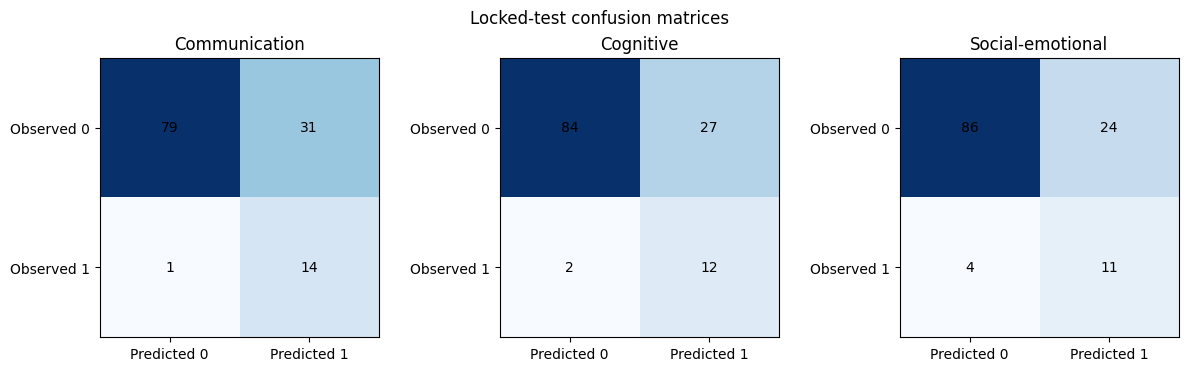

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
for axis, target in zip(axes, domain_order):
    counts = final['domains'][target]['metrics']['confusion_matrix']
    matrix = [[counts['true_negative'], counts['false_positive']],
              [counts['false_negative'], counts['true_positive']]]
    axis.imshow(matrix, cmap='Blues')
    for row in range(2):
        for column in range(2):
            axis.text(column, row, matrix[row][column], ha='center', va='center')
    axis.set_xticks([0, 1], labels=['Predicted 0', 'Predicted 1'])
    axis.set_yticks([0, 1], labels=['Observed 0', 'Observed 1'])
    axis.set_title(decision['domains'][target]['display_name'])
fig.suptitle('Locked-test confusion matrices')
plt.show()

## Objective interpretation and limitations

- The communication model correctly identified 14 of the 15 concern cases, giving 93.33% sensitivity. It also produced 31 false-positive results.
- The cognitive model correctly identified 12 of the 14 concern cases, giving 85.71% sensitivity. It produced 27 false-positive results.
- The social-emotional model correctly identified 11 of the 15 concern cases, giving 73.33% sensitivity. It produced 24 false-positive results.
- There were only 14 or 15 positive cases in each domain. Therefore, the sensitivity confidence intervals are wide, and these percentages should not be assumed to represent guaranteed performance for other children.
- Precision was approximately 31% for each domain. The high negative predictive values should also be interpreted carefully because concern cases were uncommon in this test set.
- The five model configurations were defined before comparison and were not exhaustively tuned. Therefore, this research does not claim that they are the best possible configurations.
- The overall concern result is calculated using a logical OR across the three domain decisions. It is not a fourth trained model or a separate probability.
- A new independent group of participants would be needed before making claims about general clinical reliability or deployment readiness.

In [5]:
def nested_keys(value):
    if isinstance(value, dict):
        for key, child in value.items():
            yield key; yield from nested_keys(child)
    elif isinstance(value, list):
        for child in value: yield from nested_keys(child)

prohibited = {'participant_number', 'participant_key', 'baseline_assessment_id'}
for name, report in reports.items():
    assert not prohibited.intersection(nested_keys(report)), f'Identifier found in {name}'
assert final['privacy']['participant_identifiers_in_report'] is False
assert final['privacy']['row_level_predictions_in_report'] is False
display(Markdown(f"**Privacy and provenance checks passed.** Dataset checksum: `{final['dataset_sha256']}`; split fingerprint: `{final['split_fingerprint_sha256']}`."))

**Privacy and provenance checks passed.** Dataset checksum: `464A0CD22DE10A425AAA2921D862DBC040584EB8CC51C27140B3AB5946C419B3`; split fingerprint: `BD6D8EE8BEA1D8893E2DC041F7FFF49642E70FD93019FB0DE30A9042626392F0`.